# Data Understanding of the Heart Diagnoses file

This file contains the data understanding task applied on the Heart Diagnoses CSV file.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))
from src.utils import data_understanding as du

heart_diagnoses_df = pd.read_csv("../../data/raw/heart_diagnoses_1.csv")


In [2]:
#print the number  of columns and rows of the dataset
heart_diagnoses_shape=heart_diagnoses_df.shape
print("Number of rows and columns in heart diagnoses dataset:",heart_diagnoses_shape)

Number of rows and columns in heart diagnoses dataset: (4864, 25)


In [3]:
#print the columns of the dataset 
heart_diagnoses_df_columns= du.get_cols(heart_diagnoses_df)
print("Columns in heart diagnoses dataset:",heart_diagnoses_df_columns) 

Columns in heart diagnoses dataset: ['note_id', 'subject_id', 'hadm_id', 'note_type', 'note_seq', 'charttime', 'storetime', 'HPI', 'physical_exam', 'chief_complaint', 'invasions', 'X-ray', 'CT', 'Ultrasound', 'CATH', 'ECG', 'MRI', 'reports', 'subject_id_dx', 'icd_code', 'long_title', 'gender', 'age', 'anchor_year', 'dod']


In [4]:
#print the numerical columns of the dataset
heart_diagnoses_df_num_col= heart_diagnoses_df.select_dtypes(include='number')
print("Numerical columns in heart diagnoses dataset:",heart_diagnoses_df_num_col.columns.tolist())


Numerical columns in heart diagnoses dataset: ['subject_id', 'hadm_id', 'note_seq', 'subject_id_dx', 'age', 'anchor_year']


In [5]:
#print the number of duplicate rows
heart_diagnoses_df_duplicate=du.get_num_dups(heart_diagnoses_df)
print("Number of duplicate rows in heart diagnoses dataset:", heart_diagnoses_df_duplicate)

Number of duplicate rows in heart diagnoses dataset: 0


In [6]:
#print the number of unique subject IDs
print("Number of unique subject IDs in heart diagnoses dataset:", heart_diagnoses_df['subject_id'].nunique())

Number of unique subject IDs in heart diagnoses dataset: 4392


In [7]:
#print the  missing values in each column
heart_diagnoses_df_none=du.get_cols_with_none(heart_diagnoses_df)
print("Missing values in each column of heart diagnoses dataset:\n",heart_diagnoses_df_none)

#number of missing values in each columns 
def get_num_none(df:pd.DataFrame):
  df_missing_values=df.isnull().sum()
  return df_missing_values

Missing values in each column of heart diagnoses dataset:
 note_id            False
subject_id         False
hadm_id            False
note_type          False
note_seq           False
charttime          False
storetime          False
HPI                False
physical_exam      False
chief_complaint     True
invasions           True
X-ray              False
CT                 False
Ultrasound         False
CATH               False
ECG                False
MRI                False
reports            False
subject_id_dx      False
icd_code           False
long_title         False
gender              True
age                 True
anchor_year         True
dod                 True
dtype: bool


NUMBER OF MISSING (none) VALUES PER COLUMN:

dod                4466
anchor_year        3501
age                3501
gender             3501
chief_complaint      12
invasions            12
CATH                  0
long_title            0
icd_code              0
subject_id_dx         0
reports               0
MRI                   0
ECG                   0
note_id               0
Ultrasound            0
subject_id            0
X-ray                 0
physical_exam         0
HPI                   0
storetime             0
charttime             0
note_seq              0
note_type             0
hadm_id               0
CT                    0
dtype: int64


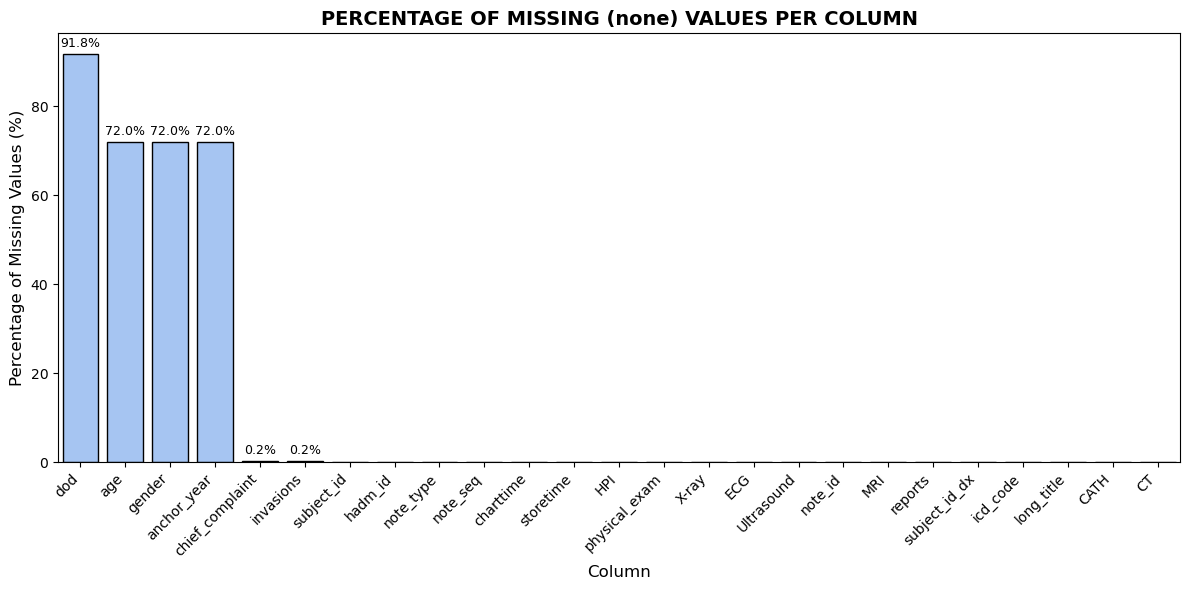


=== PERCENTAGE OF MISSING VALUES ===

dod                91.817434
age                71.977796
gender             71.977796
anchor_year        71.977796
chief_complaint     0.246711
invasions           0.246711
subject_id          0.000000
hadm_id             0.000000
note_type           0.000000
note_seq            0.000000
charttime           0.000000
storetime           0.000000
HPI                 0.000000
physical_exam       0.000000
X-ray               0.000000
ECG                 0.000000
Ultrasound          0.000000
note_id             0.000000
MRI                 0.000000
reports             0.000000
subject_id_dx       0.000000
icd_code            0.000000
long_title          0.000000
CATH                0.000000
CT                  0.000000
dtype: float64


In [8]:
# Count of None (NaN) values per column
print("NUMBER OF MISSING (none) VALUES PER COLUMN:\n")
none_counts = heart_diagnoses_df.isna().sum().sort_values(ascending=False)
print(none_counts)

# Calculate total rows
total_rows = len(heart_diagnoses_df)

# Calculate percentages
none_percentages = (none_counts / total_rows * 100).sort_values(ascending=False)

# Create DataFrame for plotting
none_df = none_percentages.reset_index()
none_df.columns = ["column", "percentage"]

# Create the plot
fig, ax = plt.subplots(figsize=(12,6))
sns.barplot(data=none_df, x="column", y="percentage", color="#99c2ff", edgecolor="black")

plt.title("PERCENTAGE OF MISSING (none) VALUES PER COLUMN", fontsize=14, fontweight='bold')
plt.xlabel("Column", fontsize=12)
plt.ylabel("Percentage of Missing Values (%)", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

# Add value labels on top of bars
for i, v in enumerate(none_df["percentage"]):
    if v > 0:  # Only show labels for columns with missing values
        ax.text(i, v + max(none_df["percentage"]) * 0.01, 
                f"{v:.1f}%", ha="center", va="bottom", fontsize=9)

plt.show()

# Print percentages
print("\n=== PERCENTAGE OF MISSING VALUES ===\n")
print(none_percentages)

In [9]:
#print the summary information of the dataset
print("Summary information of heart diagnoses dataset:")
heart_diagnoses_df.info()

Summary information of heart diagnoses dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4864 entries, 0 to 4863
Data columns (total 25 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   note_id          4864 non-null   object 
 1   subject_id       4864 non-null   int64  
 2   hadm_id          4864 non-null   int64  
 3   note_type        4864 non-null   object 
 4   note_seq         4864 non-null   int64  
 5   charttime        4864 non-null   object 
 6   storetime        4864 non-null   object 
 7   HPI              4864 non-null   object 
 8   physical_exam    4864 non-null   object 
 9   chief_complaint  4852 non-null   object 
 10  invasions        4852 non-null   object 
 11  X-ray            4864 non-null   object 
 12  CT               4864 non-null   object 
 13  Ultrasound       4864 non-null   object 
 14  CATH             4864 non-null   object 
 15  ECG              4864 non-null   object 
 16  MRI         

In [10]:
# Print the statistical summary of numerical columns
# Note: This includes all rows, meaning patients with multiple admissions are counted multiple times
print("Statistical summary of numerical columns in heart diagnoses dataset:")
heart_diagnoses_df[['note_seq','age']].describe()


Statistical summary of numerical columns in heart diagnoses dataset:


,note_seq,age
count,4864.000000,1363.000000
mean,14.690995,68.978723
std,8.260520,14.973358
min,2.000000,18.000000
25%,9.000000,60.000000
50%,14.000000,70.000000
75%,19.000000,81.000000
max,94.000000,95.000000


In [11]:
#calculate the number of hadmission for each patient
grouped_heart_diagnoses = heart_diagnoses_df.groupby('subject_id')['hadm_id'].nunique()
grouped_heart_diagnoses=grouped_heart_diagnoses.reset_index()
grouped_heart_diagnoses.columns=['subjecte_id','num_hadmissions']
print("Number of admissions for each patient in heart diagnoses dataset:\n",grouped_heart_diagnoses)
#print the max number of hadmission
max_hadmissions = grouped_heart_diagnoses['num_hadmissions'].max()
print(f"Maximum number of admissions for a single patient: {max_hadmissions}")
#print how many patient have a single hamsission
single_admission_count = (grouped_heart_diagnoses['num_hadmissions'] == 1).sum()
print(f"Number of patients with a single admission: {single_admission_count}")


Number of admissions for each patient in heart diagnoses dataset:
       subjecte_id  num_hadmissions
0        10000980                2
1        10002013                1
2        10002155                1
3        10004457                1
4        10007058                1
...           ...              ...
4387     19998596                1
4388     19998597                1
4389     19998598                1
4390     19998599                1
4391     19998600                1

[4392 rows x 2 columns]
Maximum number of admissions for a single patient: 5
Number of patients with a single admission: 4001


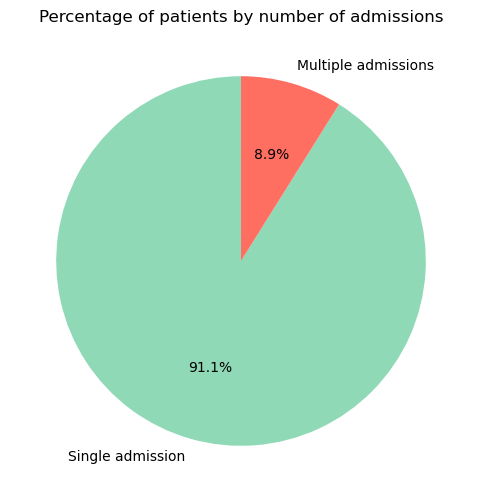

In [12]:
# Count how many admissions each patient has
admissions_per_patient = heart_diagnoses_df.groupby('subject_id')['hadm_id'].nunique()

# Classify patients: single admission vs multiple admissions
patient_groups = admissions_per_patient.apply(lambda x: 'Single admission' if x == 1 else 'Multiple admissions')

# Count patients in each group
counts = patient_groups.value_counts()

# Pie chart
plt.figure(figsize=(6,6))
plt.pie(
    counts,
    labels=counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#8fd9b6','#ff6f61']
)
plt.title("Percentage of patients by number of admissions")
plt.show()

In [13]:
#count the number of rows where the values of storetime is less or equal to the values of charttime:
#to check the data quality control that the time when the diagnosis is stored (storetime) is after or equal to the time when the diagnosis is recorded(chartime)
error = heart_diagnoses_df[heart_diagnoses_df["storetime"] < heart_diagnoses_df["charttime"]]
print("rows where the values of storetime is less  to the values of charttime:")
print(error[["subject_id", "hadm_id", "storetime", "charttime"]])
count = error.shape[0]
print("Number of rows where the values of storetime is less to the values of charttime:",count)





rows where the values of storetime is less  to the values of charttime:
      subject_id   hadm_id            storetime            charttime
249     10581759  23088729  2126-11-17 17:15:00  2126-11-18 03:00:00
340     10803096  28708257  2162-09-28 15:17:00  2162-09-29 03:00:00
683     11495932  26638278  2180-12-07 18:09:00  2180-12-08 03:00:00
1064    12223339  28882233  2162-04-25 13:46:00  2162-04-26 03:00:00
1463    13043387  25087116  2112-11-27 14:29:00  2112-11-28 03:00:00
1683    13513868  24104318  2157-05-18 15:36:00  2157-05-20 03:00:00
1727    13596021  20861215  2182-07-03 20:14:00  2182-07-04 03:00:00
1807    13767908  27341134  2166-08-02 17:45:00  2166-08-03 03:00:00
3873    18129054  20729789  2111-09-19 19:08:00  2111-09-20 03:00:00
Number of rows where the values of storetime is less to the values of charttime: 9


In [14]:
#Pint the first 10 rows of each procedure-related column. 

procedure_cols = ["CT", "MRI", "X-ray", "Ultrasound", "ECG", "CATH", "invasions"]

for col in procedure_cols:
    print(f"\nColonna: {col}")
    for i, val in enumerate(heart_diagnoses_df[col].head(10)):
        print(f"  Riga {i}: {repr(val)}")


Colonna: CT
  Riga 0: '[]'
  Riga 1: "['CHEST: ___\\n1.  Diffuse confluent ground-glass opacities predominantly in \\nthe right upper lobe and right lower lobe most likely represent \\nresidual pulmonary edema, localized to the right lung because of \\ndirection of jet in mitral \\nregurgitation.  \\n2.  Possible pulmonary hypertension. \\n3.  Moderate coronary artery disease.']"
  Riga 2: "['Chest ___.  No CT evidence for pulmonary embolus. \\n2.  Small left pleural effusion with adjacent atelectasis.  \\n3.  Possible calcified splenic artery aneurysm in the region of \\nthe hilum.']"
  Riga 3: "['anteriorly, no \\ncrackles, wheezes or rhonchi.  \\nABDOMEN: Soft, NTND. No HSM or tenderness. Abd aorta not \\nenlarged by palpation. No abdominial bruits.  \\nEXTREMITIES: No c/c/e. Femoral sheath in place in right groin.  \\nSKIN: No stasis dermatitis, ulcers, scars, or xanthomas.  \\nPULSES:  \\nRight: Carotid 2+ DP 2+ ___ 2+  \\nLeft: Carotid 2+ DP 2+ ___ 2+  \\n\\n']"
  Riga 4: "['/MR

In [15]:
# Data consistency check for patients with multiple admissions
# This analysis verifies that age and gender remain consistent across multiple admissions for the same patient

# Count how many admissions each patient has
admissions_per_patient = heart_diagnoses_df.groupby("subject_id")["hadm_id"].nunique()

# Select only patients with more than one admission
multi_admissions = admissions_per_patient[admissions_per_patient > 1].index

# Check consistency of age and gender
check_consistency = (
    heart_diagnoses_df[heart_diagnoses_df["subject_id"].isin(multi_admissions)]
    .groupby("subject_id")[["age","gender"]]
    .nunique()
)

# Show patients with more than one value for age or gender
inconsistent = check_consistency[(check_consistency["age"] > 1) | (check_consistency["gender"] > 1)]
print("Patients with inconsistencies:", inconsistent)
print("\nIf empty, this confirms that age and gender are consistent across admissions for each patient.")

# Result: Age and gender remain the same across all admissions for each patient.
# This indicates good data quality - demographic attributes are consistent as expected.

Patients with inconsistencies: Empty DataFrame
Columns: [age, gender]
Index: []

If empty, this confirms that age and gender are consistent across admissions for each patient.


In [16]:
# Percentage of gender (unique patients)
unique_patients_gender = heart_diagnoses_df.groupby("subject_id")["gender"].first().reset_index()
gender_counts = unique_patients_gender['gender'].value_counts(normalize=True) * 100
print("\n=== PERCENTAGE OF GENDER (UNIQUE PATIENTS) ===\n")
print(gender_counts)


=== PERCENTAGE OF GENDER (UNIQUE PATIENTS) ===

gender
M    57.832278
F    42.167722
Name: proportion, dtype: float64


In [17]:
# Print the number of Female, Male, and Total (F + M) and the total count with that ICD code (unique patients)
# Create a table with Female, Male, and Total counts per icd_code
# Get unique patient-ICD-gender combinations
unique_patient_icd_gender = heart_diagnoses_df[['subject_id', 'icd_code', 'gender']].drop_duplicates(subset=['subject_id', 'icd_code'])

icd_gender_counts = unique_patient_icd_gender.groupby(['icd_code', 'gender']).size().unstack(fill_value=0)
icd_gender_counts['Total'] = unique_patient_icd_gender.groupby('icd_code').size()
icd_gender_counts['Missing']= unique_patient_icd_gender.groupby('icd_code')['gender'].apply(lambda x: x.isna().sum())

# Rename columns
icd_gender_counts.columns = ['Female', 'Male', 'Total', 'Missing']

# Sort by Total (descending)
icd_gender_counts = icd_gender_counts.sort_values('Total', ascending=False)

print("=== Gender Distribution per ICD Code (unique patients) ===\n")
print(icd_gender_counts)

=== Gender Distribution per ICD Code (unique patients) ===

          Female  Male  Total  Missing
icd_code                              
I21          167   295   1382      920
I50          157   158   1296      981
I25           46    93    630      491
I48           71    74    424      279
I35           17    32    219      170
I31           30    22    152      100
I47           13    19    129       97
I30           15    12     83       56
I44           10     7     70       53
I34            4     2     50       44
I33            2     8     38       28
I49            7     6     35       22
I20            8    10     35       17
I42            4     6     33       23
I40            1     6     16        9
I24            2     5     12        5
I22            2     0      5        3
I36            1     0      1        0


In [18]:
# Associate each icd_code with the pathology name
unique_codes = heart_diagnoses_df[["icd_code", "long_title"]].drop_duplicates()
print(unique_codes)

     icd_code                                         long_title
0         I50                                      Heart failure
1         I21                        Acute myocardial infarction
4         I35                Nonrheumatic aortic valve disorders
6         I25                     Chronic ischemic heart disease
12        I48                    Atrial fibrillation and flutter
17        I47                             Paroxysmal tachycardia
31        I31                      Other diseases of pericardium
33        I44      Atrioventricular and left bundle-branch block
42        I33                    Acute and subacute endocarditis
46        I42                                     Cardiomyopathy
116       I30                                 Acute pericarditis
123       I40                                  Acute myocarditis
195       I20                                    Angina pectoris
199       I49                          Other cardiac arrhythmias
376       I24            

In [19]:
# Mean and median age for each icd_code (unique patients)
# Get unique patient-ICD combinations
unique_patient_icd_age = heart_diagnoses_df[['subject_id', 'icd_code', 'age']].drop_duplicates(subset=['subject_id', 'icd_code'])

icd_stats = unique_patient_icd_age.groupby('icd_code')['age'].agg(['mean', 'median']).reset_index()
icd_stats.columns = ['icd_code', 'mean_age', 'median_age']
print("Mean and median age for each ICD code (unique patients):\n", icd_stats)

Mean and median age for each ICD code (unique patients):
    icd_code   mean_age  median_age
0       I20  55.611111        61.0
1       I21  68.649351        69.5
2       I22  90.000000        90.0
3       I24  69.571429        69.0
4       I25  65.834532        66.0
5       I30  59.851852        59.0
6       I31  58.173077        57.5
7       I33  51.700000        59.0
8       I34  73.000000        71.0
9       I35  80.020408        83.0
10      I36  60.000000        60.0
11      I40  46.428571        52.0
12      I42  52.400000        48.5
13      I44  78.941176        84.0
14      I45        NaN         NaN
15      I46        NaN         NaN
16      I47  68.187500        69.5
17      I48  71.317241        71.0
18      I49  62.076923        64.0
19      I50  72.565079        75.0


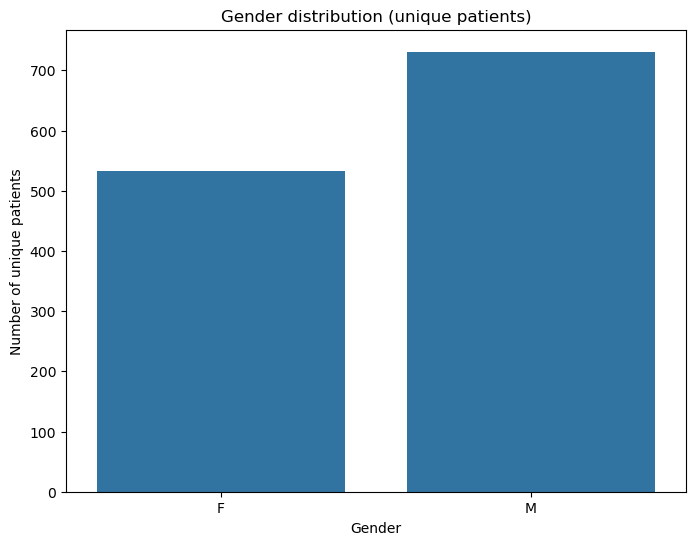

In [20]:
# Distribution of the gender column with the percentages of each gender (unique patients)
unique_patients_gender = heart_diagnoses_df.groupby("subject_id")["gender"].first().reset_index()

plt.figure(figsize=(8,6))
sns.countplot(data=unique_patients_gender, x="gender")
plt.title("Gender distribution (unique patients)")
plt.xlabel("Gender")
plt.ylabel("Number of unique patients")
plt.show()

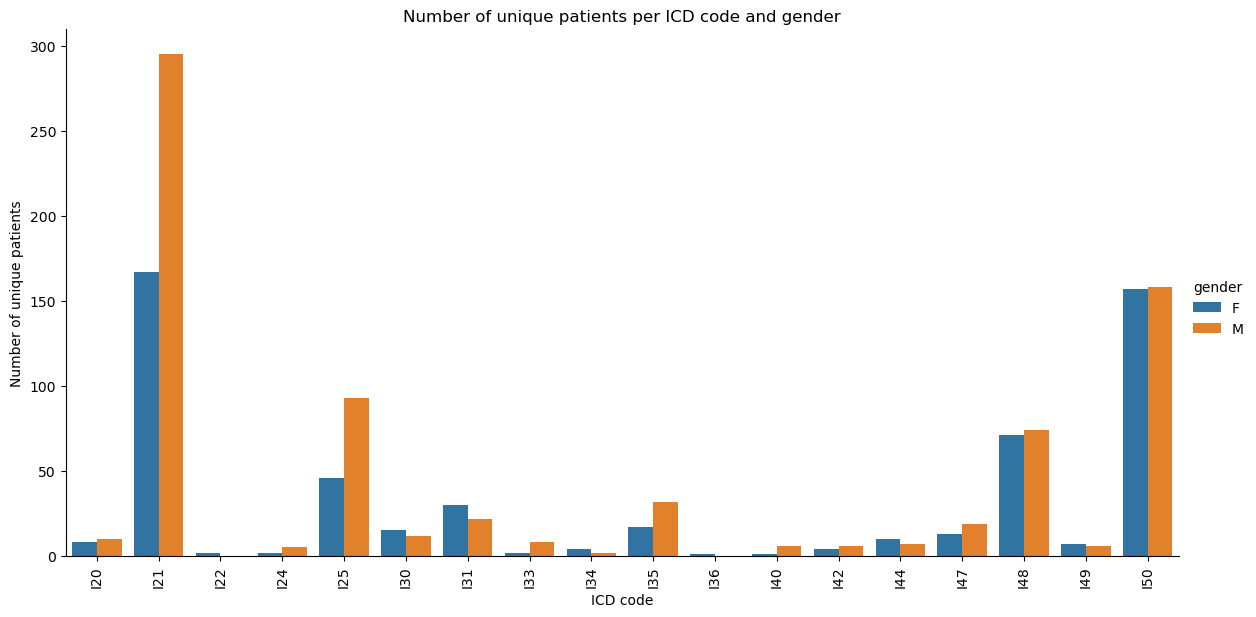

In [21]:
# Group by icd_code and gender, counting unique patients
unique_counts = (
    heart_diagnoses_df
    .groupby(["icd_code", "gender"])["subject_id"]
    .nunique()
    .reset_index()
)

# Create plot with unique counts
sns.catplot(
    data=unique_counts,
    x="icd_code",
    y="subject_id",   # now it's the number of unique patients
    hue="gender",
    kind="bar",
    height=6,
    aspect=2
)

plt.title("Number of unique patients per ICD code and gender")
plt.ylabel("Number of unique patients")
plt.xlabel("ICD code")
plt.xticks(rotation=90)
plt.show()

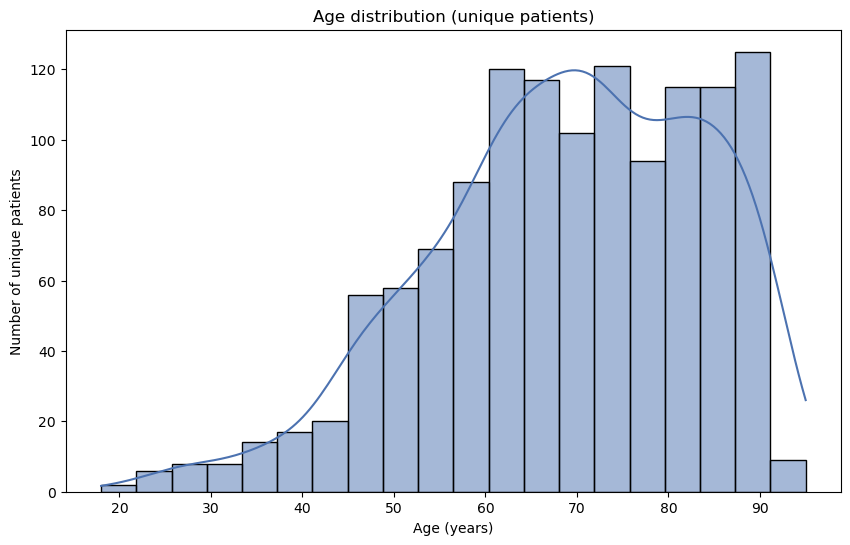

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate unique age for each patient
unique_patients = heart_diagnoses_df.groupby("subject_id")["age"].first().reset_index()

# Age histogram (unique patients)
plt.figure(figsize=(10,6))
sns.histplot(
    data=unique_patients,
    x="age",
    bins=20,
    kde=True,
    color="#4c72b0"
)

plt.title("Age distribution (unique patients)")
plt.xlabel("Age (years)")
plt.ylabel("Number of unique patients")
plt.show()

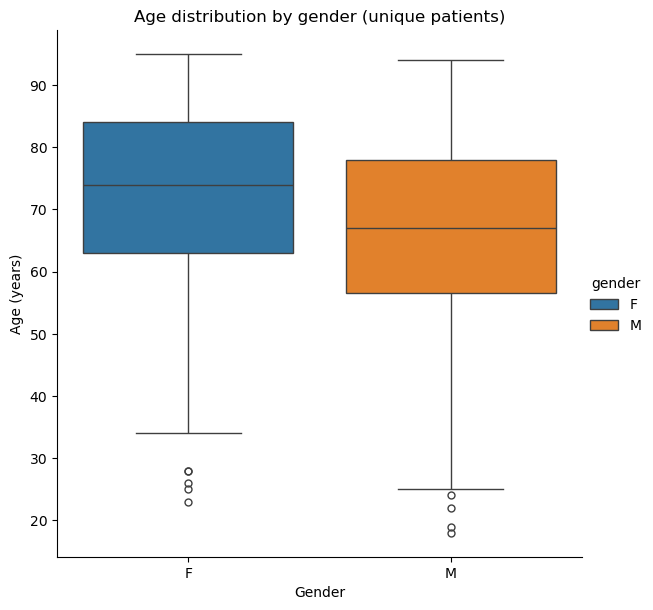

In [23]:
# Another visualization to understand the age distribution of females and males in the dataset
import seaborn as sns
import matplotlib.pyplot as plt

# Select unique age for each patient
unique_patients = heart_diagnoses_df.groupby("subject_id")[["age","gender"]].first().reset_index()

# Boxplot age vs gender (unique patients)
sns.catplot(
    data=unique_patients,
    x="gender",
    y="age",
    hue="gender",
    kind="box",
    height=6,
    aspect=1
)

plt.title("Age distribution by gender (unique patients)")
plt.xlabel("Gender")
plt.ylabel("Age (years)")
plt.show()

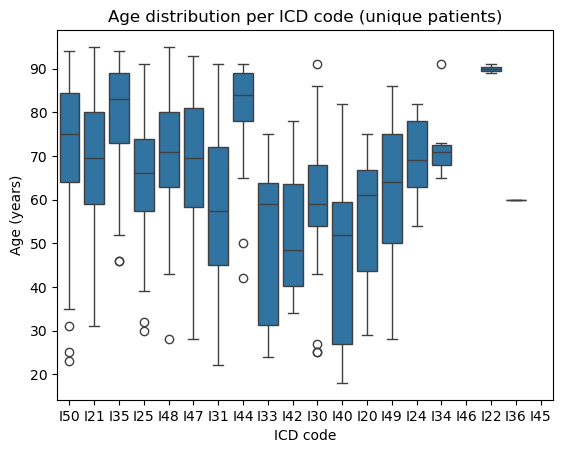

In [24]:
# Visualize age distribution for each ICD code using boxplot 
# Get unique patient-ICD combinations (a patient can appear in multiple ICD codes)
unique_patients_icd = heart_diagnoses_df[["subject_id", "icd_code", "age"]].drop_duplicates(subset=["subject_id", "icd_code"])

sns.boxplot(data=unique_patients_icd, x="icd_code", y="age")
plt.title("Age distribution per ICD code (unique patients)")
plt.xlabel("ICD code")
plt.ylabel("Age (years)")
plt.show()